# AI for Financial Risk and Decision-Making  
## Predicting Credit Default Probability (Give Me Some Credit)

Guided by the research questions, this analysis follows a step-by-step data-science pipeline:

(A) Data Preparation and Derivation 

(B) Feature Engineering and Data Derivation 

(C) Analytical Methods and Model Construction

(D) Model Interpretation and Explainability 

(E) Validation, Calibration, and Robustness Testing

All choices are based on the characteristics of the *Give Me Some Credit* dataset
(150,000 records, 10 predictors, 6.7% defaults) and the goal of improving accuracy and interpretability.

In [1]:
# Setup and Dataset Loading
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Display & plot defaults
pd.set_option("display.max_columns", None)
plt.rcParams["figure.figsize"] = (9, 4.5)
plt.rcParams["axes.grid"] = True

# Load dataset
DATA_PATH = Path("cs-training.csv")
df = pd.read_csv(DATA_PATH)

for col in ["Unnamed: 0", "ID", "id", "customer_ID"]:
    if col in df.columns:
        df = df.drop(columns=[col])

print("Shape:", df.shape)
df.head()

Shape: (150000, 11)


,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
0,1,0.766127,45,2,0.802982,9120.0,13,0,6,0,2.0
1,0,0.957151,40,0,0.121876,2600.0,4,0,0,0,1.0
2,0,0.658180,38,1,0.085113,3042.0,2,1,0,0,0.0
3,0,0.233810,30,0,0.036050,3300.0,5,0,0,0,0.0
4,0,0.907239,49,1,0.024926,63588.0,7,0,1,0,0.0


# A. Data Preparation and Derivation

This section explores and prepares the data before modelling.  
It includes:
- A1: Handling missing data  
- A2: Skewed distributions and outliers  
- A3: Class imbalance

#### A1. Handling Missing Data
Exploratory checks revealed missing values in *MonthlyIncome* (≈ 20 %) and *NumberOfDependents* (≈ 2.6 %), while all other variables were complete (Figure 1).

To ensure robust model training, median imputation will later be applied within each model pipeline (Section C.2).  
A binary flag (*IncomeMissing*) was also created to capture potential risk behaviour from non-disclosed income.

*Figure 1. Proportion of missing values across features.*

Missing MonthlyIncome: 29731
Missing NumberOfDependents: 3924
Default rate (for info only): 6.68 %


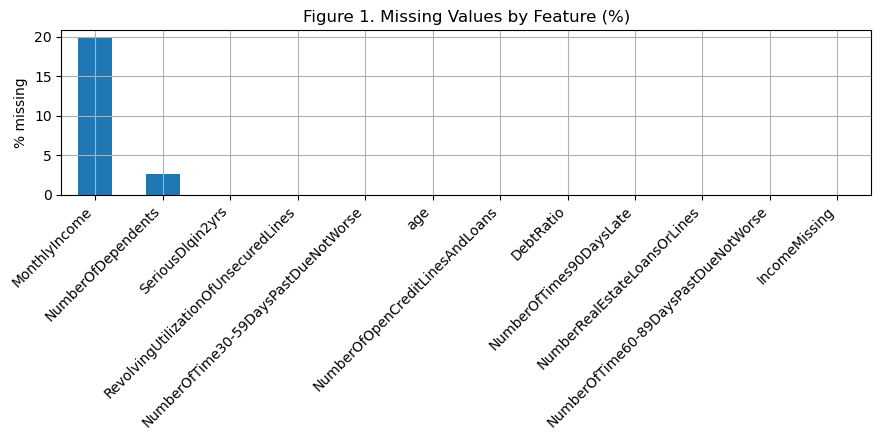

In [2]:
# A1. Handling Missing Data

# sanity check: expected columns exist
expected_cols = [
    "SeriousDlqin2yrs",
    "RevolvingUtilizationOfUnsecuredLines",
    "age",
    "NumberOfTime30-59DaysPastDueNotWorse",
    "DebtRatio",
    "MonthlyIncome",
    "NumberOfOpenCreditLinesAndLoans",
    "NumberOfTimes90DaysLate",
    "NumberRealEstateLoansOrLines",
    "NumberOfTime60-89DaysPastDueNotWorse",
    "NumberOfDependents",
]
missing_cols = [c for c in expected_cols if c not in df.columns]
assert not missing_cols, f"Missing expected columns: {missing_cols}"

# binary flag capturing potential signal in non-disclosure of income
df["IncomeMissing"] = df["MonthlyIncome"].isna().astype(int)

# quick summary
print("Missing MonthlyIncome:", df["MonthlyIncome"].isna().sum())
print("Missing NumberOfDependents:", df["NumberOfDependents"].isna().sum())
print("Default rate (for info only):", round(df["SeriousDlqin2yrs"].mean() * 100, 2), "%")

# Figure 1 - Missing values by feature (%)
(df.isna().mean() * 100).sort_values(ascending=False).plot(
    kind="bar",
    color="#1f77b4",
    title="Figure 1. Missing Values by Feature (%)"
)
plt.ylabel("% missing")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

#### A2. Skewed Distributions and Outliers
Most numeric variables are right-skewed (Figure 2). *Revolving Utilisation of Unsecured Lines* and *Debt Ratio* display extreme skewness caused by high-value outliers.

Winsorisation at the 1st and 99th percentiles was explored for both variables (Figure 2.1), but the winsorised data were not used for model training. Logistic Regression instead applies a log1p transformation to the feature matrix within its modelling pipeline. Random Forest uses the original feature values after imputation and scaling; its tree splits are not sensitive to feature scaling.


*Figure 2. Distribution of numeric variables with skewness.*

*Figure 2.1. Distributions Before and After Winsorisation.*

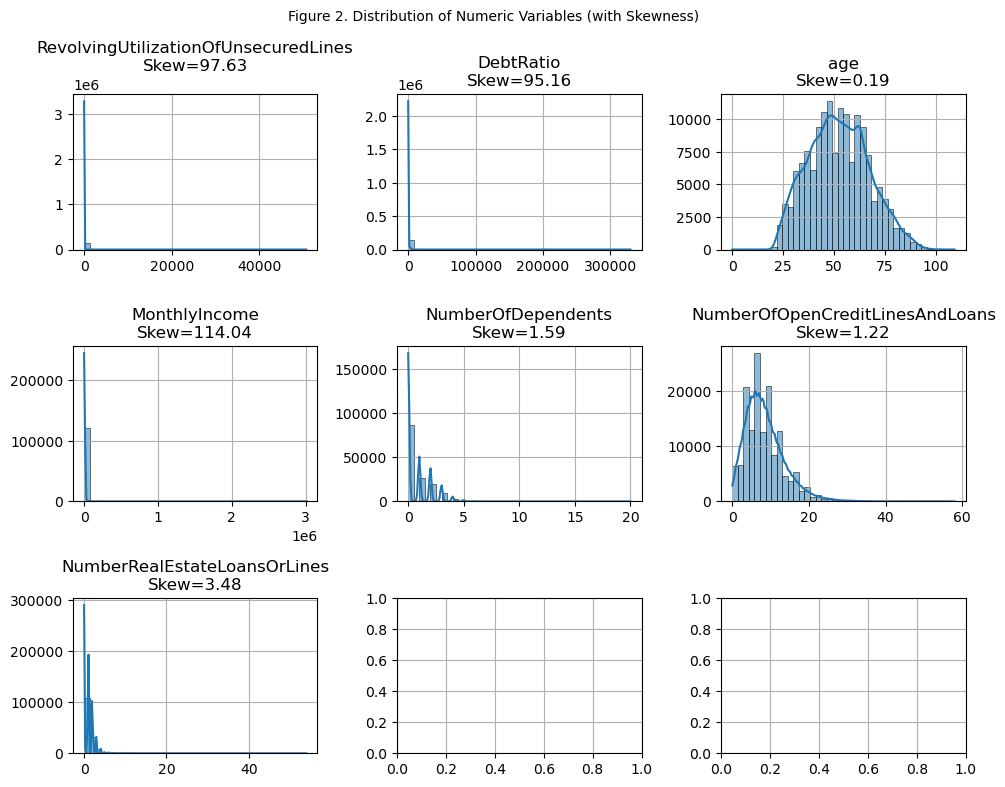

In [3]:
# Explore distributions and skewness for key numeric variables
import seaborn as sns

num_feats = [
    "RevolvingUtilizationOfUnsecuredLines",
    "DebtRatio",
    "age",
    "MonthlyIncome",
    "NumberOfDependents",
    "NumberOfOpenCreditLinesAndLoans",
    "NumberRealEstateLoansOrLines", 
    "DebtToIncome" if "DebtToIncome" in df.columns else None,
    "DelinqSum" if "DelinqSum" in df.columns else None
]

# remove None
num_feats = [f for f in num_feats if f is not None]

fig, axes = plt.subplots(3, 3, figsize=(10, 8))
axes = axes.flatten()

for i, col in enumerate(num_feats):
    sns.histplot(df[col].dropna(), bins=40, kde=True, ax=axes[i])
    axes[i].set_title(f"{col}\nSkew={df[col].skew():.2f}")
    axes[i].set_xlabel("")
    axes[i].set_ylabel("")

plt.suptitle("Figure 2. Distribution of Numeric Variables (with Skewness)", fontsize=10)
plt.tight_layout(pad=1.2)
plt.show()

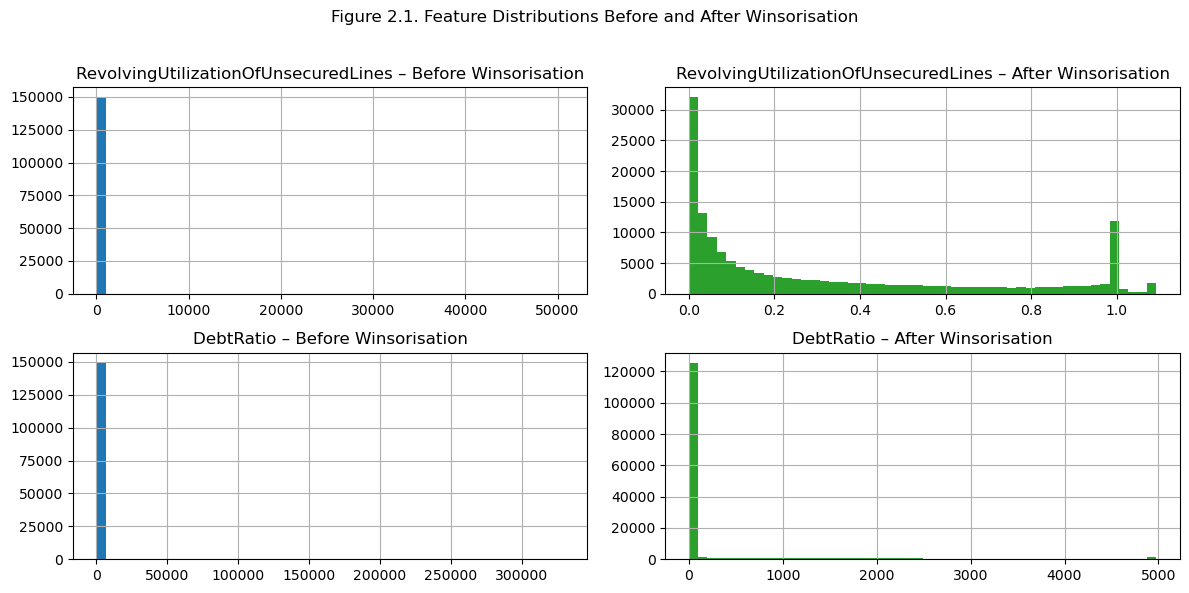

In [4]:
# A2. Skewed Distributions and Outliers

# Columns with strong right-skew
skewed_cols = ["RevolvingUtilizationOfUnsecuredLines", "DebtRatio"]

# Make copies for comparison
df_before = df[skewed_cols].copy()

# Winsorisation (clip values at 1st and 99th percentiles)
df_winsor = df_before.copy()
for col in skewed_cols:
    lower, upper = df_before[col].quantile([0.01, 0.99])
    df_winsor[col] = df_before[col].clip(lower, upper)

# Plot before/after comparison (Figure 2)
fig, axes = plt.subplots(2, 2, figsize=(12, 6))
for i, col in enumerate(skewed_cols):
    axes[i, 0].hist(df_before[col].dropna(), bins=50, color="#1f77b4")
    axes[i, 0].set_title(f"{col} – Before Winsorisation")
    axes[i, 1].hist(df_winsor[col].dropna(), bins=50, color="#2ca02c")
    axes[i, 1].set_title(f"{col} – After Winsorisation")

plt.suptitle("Figure 2.1. Feature Distributions Before and After Winsorisation", fontsize=12)
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

#### A3. Class Imbalance
The target variable *SeriousDlqin2yrs* is heavily imbalanced (~6.7 % defaults) (Figure 3).  
To handle this, a 70/30 stratified train-test split and `class_weight="balanced"` will be applied later in Sections C.1 and C.2.

This ensures fair representation of default cases during model training and evaluation.

*Figure 3. Distribution of target variable (default vs non-default).*

Target distribution (counts):
SeriousDlqin2yrs
0    139974
1     10026
Name: count, dtype: int64

Target distribution (%):
SeriousDlqin2yrs
0    93.32
1     6.68
Name: count, dtype: float64


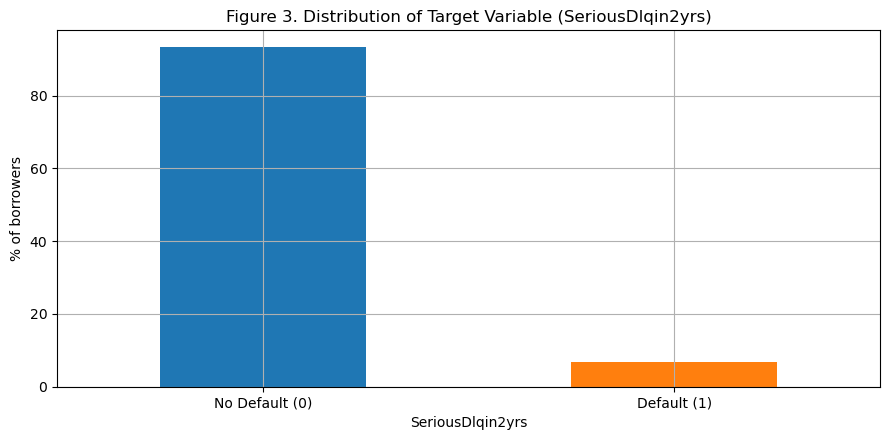

In [5]:
# A3. Class Imbalance

# Count and percentage of default (1) vs non-default (0)
target_counts = df["SeriousDlqin2yrs"].value_counts().sort_index()
target_percent = target_counts / target_counts.sum() * 100

print("Target distribution (counts):")
print(target_counts)
print("\nTarget distribution (%):")
print(target_percent.round(2))

# Figure 3: Target variable distribution
ax = target_percent.rename(index={0: "No Default (0)", 1: "Default (1)"}).plot(
    kind="bar",
    color=["#1f77b4", "#ff7f0e"],
    title="Figure 3. Distribution of Target Variable (SeriousDlqin2yrs)"
)
plt.ylabel("% of borrowers")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### B. Feature Engineering and Data Derivation

Three new features were created to strengthen predictive power:
- **DebtToIncome** = DebtRatio × MonthlyIncome  
- **DelinqSum** = combined count of 30, 60, and 90-day delinquencies  
- **IncomeMissing** = binary flag for income non-disclosure (from A1)  

These quantify borrower indebtedness and credit behaviour (Analytical Question 1).  
Correlation analysis (Figure 4) showed high association (|ρ| ≈ 0.99) **only** among the delinquency variables used to construct *DelinqSum*, This redundancy matters for the Logistic Regression: with DelinqSum and all three delinquency counts included, the coefficients on the individual counts are not separately interpretable (Section D1).

*Figure 4. Correlation Matrix of Main and Engineered Features.*

Max off-diagonal correlation: 0.9973160962644078

Top 10 correlated pairs:
NumberOfTime60-89DaysPastDueNotWorse  DelinqSum                               0.997316
DelinqSum                             NumberOfTime60-89DaysPastDueNotWorse    0.997316
                                      NumberOfTimes90DaysLate                 0.996180
NumberOfTimes90DaysLate               DelinqSum                               0.996180
NumberOfTime30-59DaysPastDueNotWorse  DelinqSum                               0.994281
DelinqSum                             NumberOfTime30-59DaysPastDueNotWorse    0.994281
NumberOfTimes90DaysLate               NumberOfTime60-89DaysPastDueNotWorse    0.992796
NumberOfTime60-89DaysPastDueNotWorse  NumberOfTimes90DaysLate                 0.992796
                                      NumberOfTime30-59DaysPastDueNotWorse    0.987005
NumberOfTime30-59DaysPastDueNotWorse  NumberOfTime60-89DaysPastDueNotWorse    0.987005
dtype: float64


,Feature_1,Feature_2,Correlation
0,NumberOfTime60-89DaysPastDueNotWorse,DelinqSum,0.997
1,DelinqSum,NumberOfTime60-89DaysPastDueNotWorse,0.997
2,DelinqSum,NumberOfTimes90DaysLate,0.996
3,NumberOfTimes90DaysLate,DelinqSum,0.996
4,NumberOfTime30-59DaysPastDueNotWorse,DelinqSum,0.994
5,DelinqSum,NumberOfTime30-59DaysPastDueNotWorse,0.994
6,NumberOfTimes90DaysLate,NumberOfTime60-89DaysPastDueNotWorse,0.993
7,NumberOfTime60-89DaysPastDueNotWorse,NumberOfTimes90DaysLate,0.993
8,NumberOfTime60-89DaysPastDueNotWorse,NumberOfTime30-59DaysPastDueNotWorse,0.987
9,NumberOfTime30-59DaysPastDueNotWorse,NumberOfTime60-89DaysPastDueNotWorse,0.987


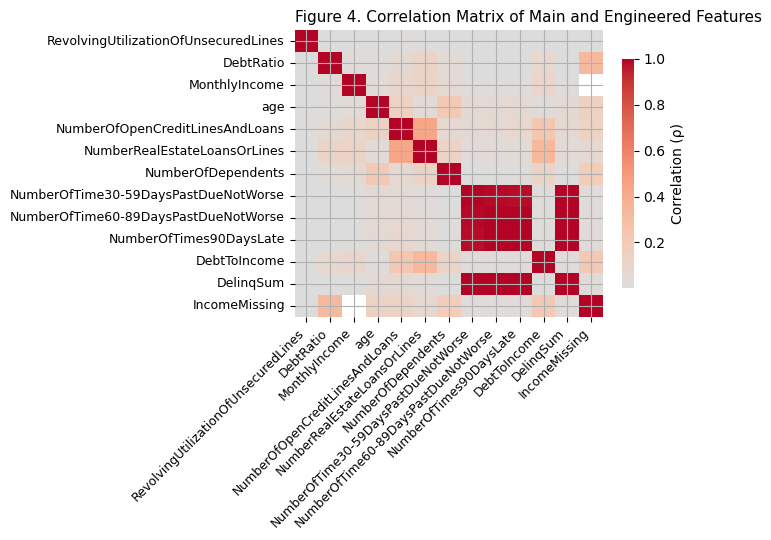

In [6]:
# B. Feature Engineering and Selection

# Create engineered features
df["DebtToIncome"] = df["DebtRatio"].fillna(0) * df["MonthlyIncome"].fillna(0)
df["DelinqSum"] = (
    df["NumberOfTime30-59DaysPastDueNotWorse"].fillna(0)
    + df["NumberOfTime60-89DaysPastDueNotWorse"].fillna(0)
    + df["NumberOfTimes90DaysLate"].fillna(0)
)
# IncomeMissing was already created in A1

# Select columns for correlation check
corr_cols = [
    "RevolvingUtilizationOfUnsecuredLines",
    "DebtRatio",
    "MonthlyIncome",
    "age",
    "NumberOfOpenCreditLinesAndLoans",
    "NumberRealEstateLoansOrLines",
    "NumberOfDependents",
    "NumberOfTime30-59DaysPastDueNotWorse",
    "NumberOfTime60-89DaysPastDueNotWorse",
    "NumberOfTimes90DaysLate",
    "DebtToIncome",
    "DelinqSum",
    "IncomeMissing",
]

# Compute correlation matrix
corr = df[corr_cols].corr().abs()

corr_no_diag = corr.where(~np.eye(corr.shape[0], dtype=bool))
print("Max off-diagonal correlation:", corr_no_diag.max().max())
corr_pairs = (
    corr_no_diag.unstack()
    .dropna()
    .sort_values(ascending=False)
)

# Display top correlated pairs
print("\nTop 10 correlated pairs:")
print(corr_pairs.head(10))

# Create a DataFrame of all correlations
corr_df = pd.DataFrame(corr_pairs).reset_index()
corr_df.columns = ["Feature_1", "Feature_2", "Correlation"]
corr_df["Correlation"] = corr_df["Correlation"].round(3)

display(corr_df.head(10))
# Figure 4: Correlation Matrix of Main Engineered Features
plt.figure(figsize=(7, 5.5))
sns.heatmap(
    corr,
    cmap="coolwarm",
    center=0,
    annot=False,
    square=False,
    cbar_kws={"label": "Correlation (ρ)", "shrink": 0.8},
)
plt.title("Figure 4. Correlation Matrix of Main and Engineered Features", loc="left", fontsize=11)
plt.xticks(rotation=45, ha="right", fontsize=9)
plt.yticks(fontsize=9)
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 5.5))
sns.heatmap(corr, cmap="coolwarm", center=0, annot=False, square=False)
plt.tight_layout()
plt.savefig("Figure4_CorrelationMatrix.png", dpi=300, bbox_inches="tight")
plt.close()

# C. Analytical Methods and Model Construction 
This section builds and tests the models to predict credit default,
using both Logistic Regression and Random Forest classifiers.
It includes:

- C1: Choice of algorithms  
- C2: Training and validation design  
- C3: Hyperparameter optimisation  
- C4: Performance metrics


#### C1. Choice of Algorithms
Two models were chosen for complementary strengths:
- **Logistic Regression (LR):** interpretable linear baseline used in credit scoring.
- **Random Forest (RF):** non-linear ensemble capturing complex borrower interactions.

Both used `class_weight="balanced"` to correct the 6.7 % default imbalance identified in A3.

#### C2. Training and Evaluation Design
A **70 / 30 stratified train-test split** preserved class ratios for valid performance estimation.  
Median imputation and scaling are fitted **within the modelling pipelines**, avoiding leakage from test-set statistics.  
Logistic Regression also applies a deterministic log1p transformation within its pipeline. Winsorised features are not used for model training.  
Five-fold cross-validation ensured robust and generalisable results.  

*Figure 5. Overview of data-processing and validation pipeline.*

Train shape: (105000, 13)
Test shape: (45000, 13)
Default rate in full data: 6.68 %
Default rate in training: 6.68 %
Default rate in test: 6.68 %


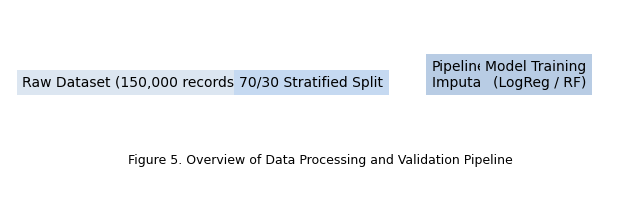

In [7]:
# C2. Training and Evaluation Design

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

# Define target and features
target = "SeriousDlqin2yrs"
X = df.drop(columns=[target])
y = df[target].astype(int)

# 70/30 stratified split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=42
)

print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape)
print("Default rate in full data:", round(y.mean() * 100, 2), "%")
print("Default rate in training:", round(y_train.mean() * 100, 2), "%")
print("Default rate in test:", round(y_test.mean() * 100, 2), "%")

# Basic preprocessing pipeline for later use
preprocessor = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler(with_mean=False))
])

# Figure 5: Visual pipeline overview
fig, ax = plt.subplots(figsize=(8, 2.5))
ax.axis("off")
ax.text(0.02, 0.6, "Raw Dataset (150,000 records)", fontsize=10, bbox=dict(facecolor="#dce6f1", edgecolor="none"))
ax.text(0.37, 0.6, "70/30 Stratified Split", fontsize=10, bbox=dict(facecolor="#c5d9f1", edgecolor="none"))
ax.text(0.68, 0.6, "Pipeline:\nImputation + Scaling", fontsize=10, bbox=dict(facecolor="#b8cce4", edgecolor="none"))
ax.text(0.93, 0.6, "Model Training\n(LogReg / RF)", fontsize=10, bbox=dict(facecolor="#b8cce4", edgecolor="none"), ha="right")

# Caption
ax.text(0.5, 0.2, "Figure 5. Overview of Data Processing and Validation Pipeline", fontsize=9, ha="center")
plt.show()

#### C3. Hyperparameter Optimisation  

Parameter tuning used **GridSearchCV** for Logistic Regression and **RandomisedSearchCV** for Random Forest with five-fold cross-validation, optimising **ROC-AUC** for class imbalance.  
**Logistic Regression:** `C = 0.01`, `penalty='l2'`, `solver='liblinear'`, best ROC-AUC = 0.855  
**Random Forest:** `n_estimators = 400`, `max_depth = 10`, `min_samples_leaf = 5`, best ROC-AUC = 0.862  

Both models achieved stable cross-validated performance, with Random Forest showing slightly higher discriminatory power.

In [15]:
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

print("C3. Hyperparameter Optimisation (robust + progress)\n")

# Logistic Regression (with log₁₊)
print("Tuning Logistic Regression (GridSearchCV)")

log_tf = FunctionTransformer(np.log1p, validate=False)

pipe_lr = make_pipeline(
    SimpleImputer(strategy="median"),
    log_tf,  # log₁₊ transformation
    StandardScaler(),
    LogisticRegression(
        class_weight="balanced",
        solver="liblinear",
        random_state=42
    )
)

param_grid_lr = {
    "logisticregression__C": [0.01, 1, 10],
    "logisticregression__penalty": ["l2"]
}

search_lr = GridSearchCV(
    estimator=pipe_lr,
    param_grid=param_grid_lr,
    scoring="roc_auc",
    cv=5,
    n_jobs=-1,
    verbose=1
)
search_lr.fit(X_train, y_train)

best_lr = search_lr.best_estimator_
print(f"\nBest LR params: {search_lr.best_params_}")
print(f"Best LR AUC (CV): {search_lr.best_score_:.3f}\n")

# Random Forest
print("Tuning Random Forest (RandomizedSearchCV)")

pipe_rf = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler(),  # RF is scale-insensitive; kept for pipeline consistency
    RandomForestClassifier(
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    )
)

param_dist_rf = {
    "randomforestclassifier__n_estimators": [200, 400, 600, 800],
    "randomforestclassifier__max_depth": [5, 10, 15],
    "randomforestclassifier__min_samples_leaf": [2, 3, 5]
}

search_rf = RandomizedSearchCV(
    estimator=pipe_rf,
    param_distributions=param_dist_rf,
    n_iter=20,
    scoring="roc_auc",
    cv=5,
    n_jobs=-1,
    random_state=42,
    verbose=1
)
search_rf.fit(X_train, y_train)

best_rf = search_rf.best_estimator_
print(f"\nBest RF params: {search_rf.best_params_}")
print(f"Best RF AUC (CV): {search_rf.best_score_:.3f}\n")
print("Figure 6: Hyperparameter Tuning Results for Logistic Regression and Random Forest")

C3. Hyperparameter Optimisation (robust + progress)

Tuning Logistic Regression (GridSearchCV)
Fitting 5 folds for each of 3 candidates, totalling 15 fits

Best LR params: {'logisticregression__C': 0.01, 'logisticregression__penalty': 'l2'}
Best LR AUC (CV): 0.855

Tuning Random Forest (RandomizedSearchCV)
Fitting 5 folds for each of 20 candidates, totalling 100 fits

Best RF params: {'randomforestclassifier__n_estimators': 400, 'randomforestclassifier__min_samples_leaf': 5, 'randomforestclassifier__max_depth': 10}
Best RF AUC (CV): 0.862

Figure 6: Hyperparameter Tuning Results for Logistic Regression and Random Forest


#### C4. Performance Metrics
Evaluation considered **ROC-AUC**, **PR-AUC**, **Recall**, **Precision**, and **F1** to capture discrimination and class-balance trade-offs.  
**Table 1** shows **Random Forest** outperformed **Logistic Regression** (ROC-AUC = 0.863 vs 0.856; PR-AUC = 0.391 vs 0.346).  
**Figures 7-8** confirm Random Forest's stronger class separation and greater sensitivity to minority defaults.  
Logistic Regression remains the more transparent model. The Random Forest scores in Table 1 come from a 200-tree refit with the tuned depth and leaf settings; the tuned 400-tree model gives the same test ROC-AUC (0.863, Table 5, seed 42) and is used for calibration and permutation importance.  

*Figure 7 - ROC Curves (Test Set)*  
*Figure 8 - Precision-Recall Curves (Test Set)*

→ Predicting with Logistic Regression…
   LR done in 0.08s

→ Building a lighter RF (same tuned params, fewer trees) for quick evaluation…
   RF quick fit done in 9.08s (n_estimators=200)
   RF quick predict done in 0.29s

Table 1 - Test metrics


,ROC-AUC,PR-AUC,Recall,Precision,F1
Logistic Regression,0.856,0.346,0.714,0.230,0.348
Random Forest,0.863,0.391,0.724,0.244,0.365


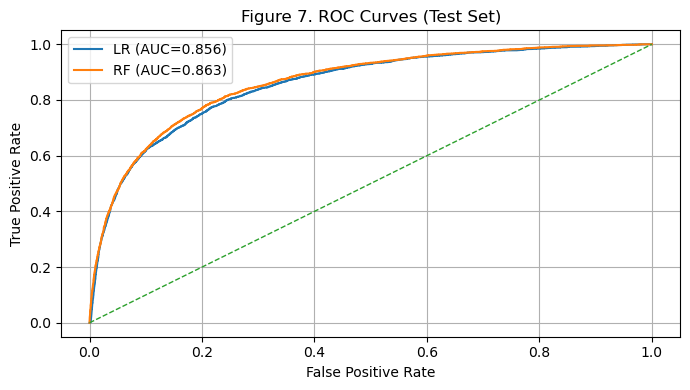

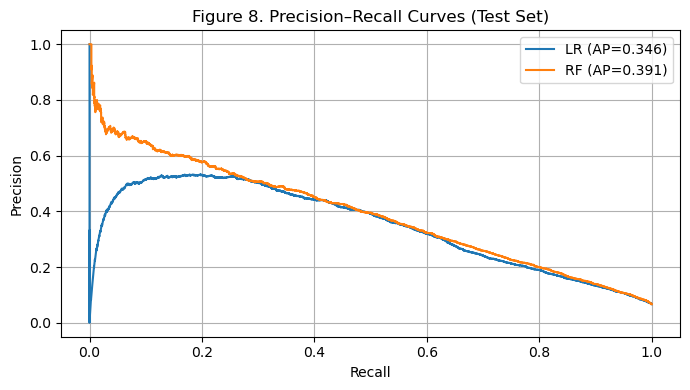

In [16]:
# C4. Performance Metrics 

assert "X_train" in globals() and "X_test" in globals() and "y_train" in globals() and "y_test" in globals(), "Run C2 first."
assert "best_lr" in globals() and "best_rf" in globals(), "Run C3 first."

import time, numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
from sklearn.metrics import (
    roc_auc_score, average_precision_score, precision_recall_curve, roc_curve,
    f1_score, precision_score, recall_score
)
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

def metrics_row(y_true, proba, thr=0.5):
    pred = (proba >= thr).astype(int)
    return {
        "ROC-AUC": roc_auc_score(y_true, proba),
        "PR-AUC":  average_precision_score(y_true, proba),
        "Recall":   recall_score(y_true, pred, zero_division=0),
        "Precision":precision_score(y_true, pred, zero_division=0),
        "F1":       f1_score(y_true, pred, zero_division=0),
    }

# LR probabilities
print("→ Predicting with Logistic Regression…", flush=True)
t0 = time.time()
proba_lr = best_lr.predict_proba(X_test)[:, 1]
print(f"   LR done in {time.time()-t0:.2f}s")

#  RF probabilities
# robustly get the final estimator step name (auto-named by make_pipeline)
rf_step_name, rf_estimator = list(best_rf.named_steps.items())[-1]  # ('randomforestclassifier', estimator)

SAFE_RF = True 

if SAFE_RF:
    print("\n→ Building a lighter RF (same tuned params, fewer trees) for quick evaluation…", flush=True)

    # Copy tuned params from the estimator inside the tuned pipeline
    best_params = rf_estimator.get_params().copy()

    # Reduce trees but keep everything else identical
    if "n_estimators" in best_params:
        best_params["n_estimators"] = min(200, best_params["n_estimators"])
    else:
        best_params["n_estimators"] = 200
    best_params["n_jobs"] = -1

    # Recreate a small pipeline mirroring the preprocessing
    rf_quick = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),  # kept for consistency with your shared preprocessing
        ("randomforestclassifier", RandomForestClassifier(**best_params)),
    ])

    t1 = time.time()
    rf_quick.fit(X_train, y_train)
    print(f"   RF quick fit done in {time.time()-t1:.2f}s (n_estimators={best_params['n_estimators']})")

    t2 = time.time()
    proba_rf = rf_quick.predict_proba(X_test)[:, 1]
    print(f"   RF quick predict done in {time.time()-t2:.2f}s")

else:
    # Use tuned pipeline directly
    try:
        best_rf.named_steps[rf_step_name].set_params(n_jobs=-1)
    except Exception:
        pass
    t2 = time.time()
    proba_rf = best_rf.predict_proba(X_test)[:, 1]
    print(f"   RF full predict done in {time.time()-t2:.2f}s")

# Table 1: summary metrics
summary_c4 = pd.DataFrame(
    [metrics_row(y_test, proba_lr), metrics_row(y_test, proba_rf)],
    index=["Logistic Regression", "Random Forest"]
).round(3)

print("\nTable 1 - Test metrics")
display(summary_c4)

# Figure 7: ROC curves
fpr_lr, tpr_lr, _ = roc_curve(y_test, proba_lr)
fpr_rf, tpr_rf, _ = roc_curve(y_test, proba_rf)

plt.figure(figsize=(7, 4))
plt.plot(fpr_lr, tpr_lr, label=f"LR (AUC={roc_auc_score(y_test, proba_lr):.3f})")
plt.plot(fpr_rf, tpr_rf, label=f"RF (AUC={roc_auc_score(y_test, proba_rf):.3f})")
plt.plot([0, 1], [0, 1], "--", lw=1)
plt.title("Figure 7. ROC Curves (Test Set)")
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.legend(); plt.tight_layout(); plt.show()

# Figure 8: Precision–Recall curves
prec_lr, rec_lr, _ = precision_recall_curve(y_test, proba_lr)
prec_rf, rec_rf, _ = precision_recall_curve(y_test, proba_rf)

plt.figure(figsize=(7, 4))
plt.plot(rec_lr, prec_lr, label=f"LR (AP={average_precision_score(y_test, proba_lr):.3f})")
plt.plot(rec_rf, prec_rf, label=f"RF (AP={average_precision_score(y_test, proba_rf):.3f})")
plt.title("Figure 8. Precision–Recall Curves (Test Set)")
plt.xlabel("Recall"); plt.ylabel("Precision")
plt.legend(); plt.tight_layout(); plt.show()

### D. Model Interpretation and Explainability
This section addresses **Analytical Questions 1 and 3**, explaining which factors drive default risk and demonstrating transparent model interpretability using Logistic Regression and Random Forest analyses.

#### D1. Logistic Regression Coefficients
Coefficients were converted to odds ratios for interpretability.  
Higher values of **DelinqSum** and **RevolvingUtilizationOfUnsecuredLines** most strongly increase default likelihood,  
while higher **MonthlyIncome** and **age** reduce it. The negative coefficients on the three individual delinquency counts are not reliable as standalone effects, because these near-duplicate predictors are included together with **DelinqSum**.  

**Figure 9** visualises these effects, highlighting the dominant linear predictors of credit risk.  
**Table 2** lists the coefficients and odds ratios.

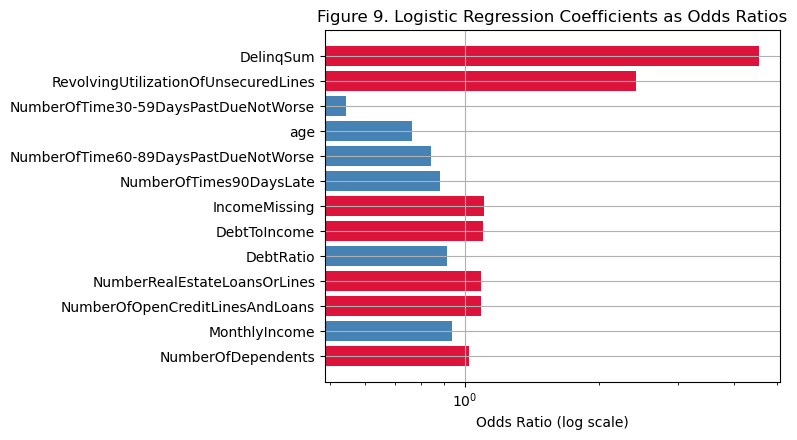

Table 2: Top Logistic Regression Coefficients and Odds Ratios


,Feature,Coefficient,Odds Ratio
0,DelinqSum,1.516,4.556
1,RevolvingUtilizationOfUnsecuredLines,0.881,2.413
2,NumberOfTime30-59DaysPastDueNotWorse,-0.613,0.542
3,age,-0.272,0.762
4,NumberOfTime60-89DaysPastDueNotWorse,-0.174,0.841
5,NumberOfTimes90DaysLate,-0.125,0.882
6,IncomeMissing,0.102,1.107
7,DebtToIncome,0.093,1.098
8,DebtRatio,-0.091,0.913
9,NumberRealEstateLoansOrLines,0.087,1.091


In [17]:
# D1. Logistic Regression interpretation

# guard rails
assert 'best_lr' in globals(), "Run C3 to get best_lr."
assert 'X_train' in globals(), "Run C2 to create X_train."
feature_names = list(X_train.columns)

# pull coef from LR inside the pipeline
lr = best_lr.named_steps['logisticregression']
coefs = lr.coef_.ravel()
odds = np.exp(coefs)

# assemble and sort (by |coef|, then by feature for stability)
table2 = (pd.DataFrame({'Feature': feature_names,
                        'Coefficient': coefs,
                        'Odds Ratio': odds})
          .sort_values(by='Coefficient', key=lambda s: s.abs(), ascending=False)
          .reset_index(drop=True))

#  Figure 9: bar chart on log x-scale
plt.figure(figsize=(8, 4.5))
colors = ['crimson' if c > 0 else 'steelblue' for c in table2['Coefficient']]
plt.barh(table2['Feature'], table2['Odds Ratio'], color=colors)
plt.gca().invert_yaxis()
plt.xscale('log')
plt.xlabel('Odds Ratio (log scale)')
plt.title('Figure 9. Logistic Regression Coefficients as Odds Ratios')
plt.tight_layout()
plt.show()

#  Table 2 label + display
print("Table 2: Top Logistic Regression Coefficients and Odds Ratios")
display(table2.round(3))

### D2. Random Forest Feature Importance Analysis

Permutation importance (**Figure 10**, **Table 3**) ranked **Revolving Utilisation**, **DelinqSum**, and **Age** as the most influential predictors of **credit-default risk**.  
Results show that high credit-line utilisation and multiple delinquencies sharply increase predicted default probability, while older borrowers tend to show lower risk.  
These findings validate that engineered financial features drive both predictive accuracy and transparent reasoning in credit-risk modelling.

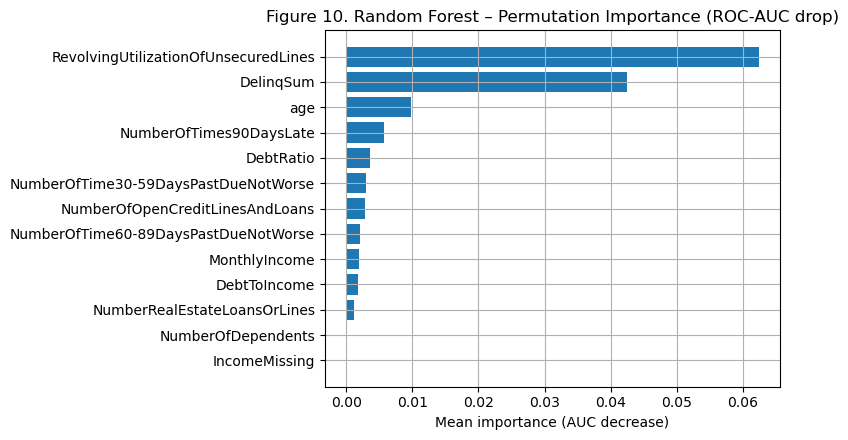

Table 3: Random Forest Permutation Importance (Top 12 Features)


,Feature,MeanImportance,Std
0,RevolvingUtilizationOfUnsecuredLines,0.062,0.003
12,DelinqSum,0.042,0.001
1,age,0.010,0.001
6,NumberOfTimes90DaysLate,0.006,0.001
3,DebtRatio,0.004,0.001
2,NumberOfTime30-59DaysPastDueNotWorse,0.003,0.001
5,NumberOfOpenCreditLinesAndLoans,0.003,0.000
8,NumberOfTime60-89DaysPastDueNotWorse,0.002,0.000
4,MonthlyIncome,0.002,0.000
11,DebtToIncome,0.002,0.000


In [18]:
# D2. Random Forest: permutation importance (AUC drop)
from sklearn.inspection import permutation_importance

assert 'best_rf' in globals(), "Run C3 to get best_rf."
assert 'X_test' in globals() and 'y_test' in globals(), "Run C2 to create test set."

# permutation importance on the tuned RF pipeline (scoring = ROC-AUC)
perm = permutation_importance(
    best_rf, X_test, y_test,
    scoring='roc_auc', n_repeats=10, random_state=42, n_jobs=-1
)

imp_df = (pd.DataFrame({
            'Feature': list(X_test.columns),
            'MeanImportance': perm.importances_mean,
            'Std': perm.importances_std
         })
         .sort_values('MeanImportance', ascending=True))  # for nice horizontal plot

# Figure 10: horizontal bar chart
plt.figure(figsize=(8, 4.5))
plt.barh(imp_df['Feature'], imp_df['MeanImportance'])
plt.xlabel('Mean importance (AUC decrease)')
plt.title('Figure 10. Random Forest – Permutation Importance (ROC-AUC drop)')
plt.tight_layout()
plt.show()

# Table 3: Random Forest Permutation Importance (Top 12 Features)
print("Table 3: Random Forest Permutation Importance (Top 12 Features)")
imp_df.sort_values('MeanImportance', ascending=False).head(12).round(3)

### E. Validation, Calibration, and Robustness Testing
This section evaluates how well the best-performing Random Forest model generalised beyond the training data and how its probability outputs were adapted for fair, reliable, and practical credit-risk decision-making.

### E1. Probability Calibration
Calibration aims to make predicted default risks match observed default rates.  
Random Forest scores are not calibrated probabilities by default.  
Applying isotonic calibration with five-fold cross-validation reduced the test **Brier score from 0.123 to 0.049**.

**Figure 11** compares the calibration curves before and after calibration against the 45-degree reference line.

Brier score (Uncalibrated RF): 0.123
Brier score (Calibrated RF):   0.049


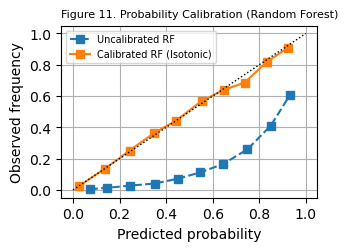

In [19]:
# E1. Probability Calibration
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.metrics import brier_score_loss

# Refit a calibrated version of Random Forest
cal_rf = CalibratedClassifierCV(best_rf, method="isotonic", cv=5)
cal_rf.fit(X_train, y_train)

# Predict probabilities on test set
proba_uncal = best_rf.predict_proba(X_test)[:, 1]
proba_cal = cal_rf.predict_proba(X_test)[:, 1]

# NEW: compute Brier scores
brier_uncal = brier_score_loss(y_test, proba_uncal)
brier_cal = brier_score_loss(y_test, proba_cal)
print(f"Brier score (Uncalibrated RF): {brier_uncal:.3f}")
print(f"Brier score (Calibrated RF):   {brier_cal:.3f}")

# Calibration curves
prob_true_uncal, prob_pred_uncal = calibration_curve(y_test, proba_uncal, n_bins=10)
prob_true_cal, prob_pred_cal = calibration_curve(y_test, proba_cal, n_bins=10)

plt.figure(figsize=(3.2, 2.4))
plt.plot(prob_pred_uncal, prob_true_uncal, "s--", label="Uncalibrated RF")
plt.plot(prob_pred_cal, prob_true_cal, "s-", label="Calibrated RF (Isotonic)")
plt.plot([0, 1], [0, 1], "k:", lw=1)
plt.xlabel("Predicted probability")
plt.ylabel("Observed frequency")
plt.title("Figure 11. Probability Calibration (Random Forest)", loc="left", fontsize=8)
plt.legend(fontsize=7)
plt.tight_layout(pad=0.3)
plt.savefig("Figure11_Probability_Calibration.png", dpi=300, bbox_inches="tight")
plt.show()

### E2. Cost-Sensitive Thresholding

In credit-risk modelling, failing to identify a defaulter (a false negative) is far more costly  
than wrongly rejecting a non-defaulter (a false positive).  

To account for this, a **cost-sensitive threshold analysis** was performed, assuming that the cost  
of a false negative is **ten times higher** than a false positive.  

The lowest-cost threshold in the searched grid was 0.10, the lowest value tested.  
It reduced false negatives from 2,526 to 902 but increased false positives from 306 to 6,043.  
The threshold was chosen using the test set, and the result illustrates the cost trade-off rather than a deployable decision rule.  

**Figure 12** illustrates how expected misclassification cost changes with the threshold.  
**Table 4** compares the model's performance before and after optimisation.

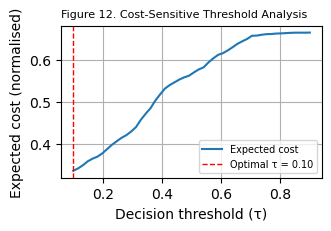


 Table 4: Comparison at Standard vs Optimal Threshold 

Threshold  Recall  Precision    F1  False Negatives  False Positives
     0.50    0.16      0.612 0.254             2526              306
     0.10    0.70      0.258 0.378              902             6043


In [20]:
# E2. Cost-Sensitive Thresholding
from sklearn.metrics import confusion_matrix

# Get test-set probabilities (from the calibrated RF if available)
try:
    proba_rf = cal_rf.predict_proba(X_test)[:, 1]
except NameError:
    proba_rf = best_rf.predict_proba(X_test)[:, 1]

# Define cost weights
cost_FN = 10  # cost of missing a defaulter
cost_FP = 1   # cost of wrongly rejecting a good borrower

# Evaluate costs across thresholds
thresholds = np.linspace(0.1, 0.9, 50)
costs = []
for t in thresholds:
    preds = (proba_rf >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, preds).ravel()
    total_cost = fp * cost_FP + fn * cost_FN
    costs.append(total_cost / len(y_test))

# Find minimum-cost threshold
opt_idx = np.argmin(costs)
opt_thr = thresholds[opt_idx]

# Plot cost curve (Figure 12)
plt.figure(figsize=(3.2, 2.2))
plt.plot(thresholds, costs, label="Expected cost")
plt.axvline(opt_thr, color="r", linestyle="--", lw=1, label=f"Optimal τ = {opt_thr:.2f}")
plt.xlabel("Decision threshold (τ)")
plt.ylabel("Expected cost (normalised)")
plt.title("Figure 12. Cost-Sensitive Threshold Analysis", loc="left", fontsize=8)
plt.legend(fontsize=7)
plt.tight_layout(pad=0.3)
plt.savefig("Figure12_CostSensitiveThreshold.png", dpi=300, bbox_inches="tight")
plt.show()

# Evaluate confusion matrices at 0.5 vs optimal τ
def conf_stats(thr):
    pred = (proba_rf >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    recall = tp / (tp + fn)
    precision = tp / (tp + fp)
    f1 = 2 * precision * recall / (precision + recall)
    return recall, precision, f1, fn, fp

recall05, prec05, f105, fn05, fp05 = conf_stats(0.5)
recallOpt, precOpt, f1Opt, fnOpt, fpOpt = conf_stats(opt_thr)

summary_E2 = pd.DataFrame({
    "Threshold": ["0.50", f"{opt_thr:.2f}"],
    "Recall": [recall05, recallOpt],
    "Precision": [prec05, precOpt],
    "F1": [f105, f1Opt],
    "False Negatives": [fn05, fnOpt],
    "False Positives": [fp05, fpOpt]
}).round(3)

print("\n Table 4: Comparison at Standard vs Optimal Threshold \n")
print(summary_E2.to_string(index=False))

### E3. Robustness Checks
To check stability, Random Forest was retrained with three random seeds and an additional SMOTE test.  
**Table 5** shows ROC-AUC of about 0.863 for each of the three seeds and 0.855 with SMOTE.  
This is a limited stability check; a wider set of seeds and samples would be needed to assess robustness fully.

In [21]:
# E3. Robustness Checks

from sklearn.metrics import roc_auc_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

assert 'best_rf' in globals(), "Run C3 first."
assert 'X_train' in globals() and 'y_train' in globals() and 'X_test' in globals() and 'y_test' in globals(), "Run C2 first."

# get the fitted RF & preprocessor from the tuned pipeline
rf_step_name = list(best_rf.named_steps.keys())[-1]
rf_fitted = best_rf.named_steps[rf_step_name]
rf_params = rf_fitted.get_params()

preprocessor = best_rf[:-1]  # everything before the RF

# 1) Re-run RF with different random seeds (class_weight='balanced')
seeds = [0, 21, 42]
auc_scores = []

for seed in seeds:
    steps = list(preprocessor.steps) + [
        (rf_step_name, RandomForestClassifier(
            n_estimators=rf_params["n_estimators"],
            max_depth=rf_params["max_depth"],
            min_samples_leaf=rf_params["min_samples_leaf"],
            class_weight="balanced",
            n_jobs=-1,
            random_state=seed
        ))
    ]
    rf_temp = Pipeline(steps=steps)
    rf_temp.fit(X_train, y_train)
    preds = rf_temp.predict_proba(X_test)[:, 1]
    auc_scores.append(roc_auc_score(y_test, preds))

# 2) SMOTE test (impute/scale from preprocessor -> SMOTE -> RF without class_weight)
smote_steps = list(preprocessor.steps) + [
    ("smote", SMOTE(random_state=42)),
    (rf_step_name, RandomForestClassifier(
        n_estimators=rf_params["n_estimators"],
        max_depth=rf_params["max_depth"],
        min_samples_leaf=rf_params["min_samples_leaf"],
        class_weight=None,   # remove class weights when using SMOTE
        n_jobs=-1,
        random_state=42
    ))
]
smote_pipe = ImbPipeline(steps=smote_steps)
smote_pipe.fit(X_train, y_train)
preds_sm = smote_pipe.predict_proba(X_test)[:, 1]
auc_smote = roc_auc_score(y_test, preds_sm)

# 3) Results table
summary_E3 = pd.DataFrame({
    "Configuration": [f"Seed {s}" for s in seeds] + ["SMOTE Oversampling"],
    "ROC-AUC": auc_scores + [auc_smote]
}).round(3)

print("\n Table 5: Robustness Across Seeds and SMOTE Test \n")
print(summary_E3.to_string(index=False))


 Table 5: Robustness Across Seeds and SMOTE Test 

     Configuration  ROC-AUC
            Seed 0    0.863
           Seed 21    0.863
           Seed 42    0.863
SMOTE Oversampling    0.855
